# Архитектура и практическое применение алгоритмов обучения с подкреплением

Обучение с подкреплением (Reinforcement Learning) представляет собой область машинного обучения, в которой автономный субъект (агент) формирует оптимальную стратегию поведения в динамической среде путем максимизации кумулятивной функции полезности (суммы вознаграждений).

Конспект содержит анализ базовых методов, математическое описание принципов их оптимизации, а также программную реализацию на базе библиотек `Gymnasium` и `Stable-Baselines3`.


## 1.  Описание алгоритмов


### 1.1 Табличный метод Q-learning

Метод относится к классу алгоритмов временных различий (*Temporal Difference learning*) и предназначен для итерационной аппроксимации функции полезности $Q(s, a)$, отражающей математическое ожидание кумулятивной полезности выполнения действия $a$ в состоянии $s$.

Пересчет временных различий выполняется по правилу стохастической аппроксимации:

$$Q_{k+1}(s, a) = (1 - \alpha) \cdot Q_k(s, a) + \alpha \cdot \hat{Q}(s, a) = Q_k(s, a) + \alpha \cdot \left( \hat{Q}(s, a) - Q_k(s, a) \right)$$

Развертывание оценки $\hat{Q}(s, a)$ через уравнение Беллмана формирует классическое правило обновления:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \cdot \left( r(s, a) + \gamma \cdot \max_{a'} Q(s', a') - Q(s, a) \right)$$

#### Операционный цикл и сбор данных
Алгоритм функционирует в рамках последовательных итераций, сгруппированных в **эпизоды** (игровые сессии от начального состояния до финального/терминального). Данные генерируются непосредственно в процессе взаимодействия со средой («на лету») по следующей схеме:

1. **Инициализация:** В начале каждого эпизода среда сбрасывается в стартовое состояние $s$.
2. **Выбор действия ($\epsilon$-greedy стратегия):** Для обеспечения баланса между исследованием среды (Exploration) и использованием накопленных знаний (Exploitation) агент генерирует случайное число $p \in [0, 1]$.
   * Если $p < \epsilon$, выбирается случайное действие $a \in A$ (стохастическое исследование).
   * Если $p \ge \epsilon$, выбирается жадное действие $a = \arg\max_{a'} Q(s, a')$ (эксплуатация).
   Параметр $\epsilon$ экспоненциально уменьшается с каждым новым эпизодом от $1.0$ до $0.01$.
3. **Получение обратной связи:** Выбранное действие $a$ передается в среду. Среда возвращает мгновенное вознаграждение $r$ и новое состояние $s'$, а также флаг завершения эпизода (`terminated` / `truncated`).
4. **Шаг обновления матрицы:** Используя полученный кортеж данных $(s, a, r, s')$, алгоритм мгновенно модифицирует конкретную ячейку $Q(s, a)$ по формуле Беллмана. Переход к следующему шагу осуществляется присвоением $s \leftarrow s'$.

#### Критерии остановки и объемы данных
Количество просматриваемых эпизодов (обычно от $1\,000$ до $10\,000$ для дискретных сред средней сложности) задается разработчиком. Процесс обучения останавливается при выполнении одного из условий:
* Достижение максимального количества эпизодов (временной критерий).
* Стабилизация матрицы: когда норма разности матрицы между итерациями $\|Q_{k+1} - Q_k\| < \delta$ стремится к нулю (критерий сходимости).

### 1.1.2 Ограничения табличного подхода и необходимость функциональной аппроксимации

Классический метод $Q$-learning не зависит от структуры пространства состояний $\mathcal{S}$ только при условии его конечности и малой размерности. При переходе к непрерывным метрическим пространствам ($\mathcal{S} \subset \mathbb{R}^d$) или задачам с высоким комбинаторным взрывом (высокоразмерные дискретные пространства) точное представление функции полезности $Q(s, a)$ в виде матрицы становится невозможным по двум причинам:

1. **Проклятие размерности (Curse of Dimensionality):** Асимптотический рост объема памяти, требуемого для хранения таблицы коэффициентов, делает вычисления нерекуррентными.
2. **Отсутствие свойства генерализации (Обобщения):** Табличный метод не способен экстраполировать накопленный опыт на не посещенные ранее точки пространства состояний, даже если они находятся в $\epsilon$-окрестности известных дискретных состояний.

Решением является переход от точного матричного представления к параметрической аппроксимации: $Q(s, a) \approx Q_\theta(s, a)$, где $\theta \in \mathbb{R}^m$ - вектор настраиваемых весов непрерывного дифференцируемого отображения, в роли которого выступает глубокая искусственная нейронная сеть (Deep Neural Network).


### 1.2 Deep Q-Networks - DQN

#### 1.2.1 Описание DQN

При переходе к непрерывным или высокоразмерным пространствам состояний функция полезности параметризуется весами $\theta$ аппроксимирующей ее нейронной сети: $Q(s, a) \approx Q_\theta(s, a)$. На каждой итерации обновление параметров следует выражению:
$$Q_\theta(s, a) \leftarrow Q_\theta(s, a) + \alpha \cdot \left( r(s, a) + \gamma \cdot \max_{a'} Q_\theta(s', a') - Q_\theta(s, a) \right)$$

Это эквивалентно решению задачи регрессии методом простой итерации для уравнения Беллмана:
$$Q^*(s, a) = r(s, a) + \gamma \mathbb{E}_{s'} \left[ \max_{a'} Q^*(s', a') \right]$$

Формализация регрессионного шага для текущей версии параметров $\theta_k$:
* **Входные данные (Признаки):** Вектор состояния среды $s$. Выходной слой сети возвращает вектор размерности $|A|$, где каждый элемент соответствует оценке пары $(s, a)$.
* **Искомое теоретическое значение:** Правая часть уравнения оптимальности Беллмана:
  $$f(s, a) = r(s, a) + \gamma \mathbb{E}_{s'} \left[ \max_{a'} Q^*(s', a') \right]$$
* **Наблюдаемое эмпирическое значение (Таргет $y$):** Одношаговая случайная реализация перехода $s' \sim p(s' | s, a)$:
  $$y(s, a) \leftarrow r(s, a) + \gamma \max_{a'} Q_{\theta_k^-}(s', a')$$
  Где $\theta_k^-$ — замороженные веса целевой сети (*Target Network*).
* **Функция потерь (Loss function):** Среднеквадричная ошибка (MSE) на батче:
  $$Loss(y, \hat{y}) = \frac{1}{2} (y - Q_\theta(s, a))^2$$
---

#### 1.2.2 Вычислительный цикл и обоснование механизмов стабилизации DQN

В отличие от классического Q-learning, глубокая сеть DQN не может обучаться непосредственно на последовательных шагах среды из-за сильной автокорреляции данных. Вычислительный цикл и математические основы его стабилизации организуются следующим образом:

1. **Сбор опыта (Data Collection):** Агент совершает шаг в среде на основе $\epsilon$-greedy стратегии с текущими весами рабочей сети $\theta$. Полученный кортеж опыта $(s_t, a_t, r_t, s_{t+1}, \text{done})$ помещается в циклический буфер памяти (**Replay Buffer**) фиксированной емкости (например, $100\,000$ переходов). Обучение сети не начинается, пока буфер не заполнится до минимального порога (`learning_starts`).
   * *Теоретическое обоснование:* Оптимизация параметров $\theta$ методом стохастического градиентного спуска (SGD) базируется на допущении о независимости и одинаковой распределенности случайных величин (i.i.d. assumption). Траекторные кортежи, генерируемые последовательно во времени, сильно скоррелированы между собой ($\text{Cov}(s_t, s_{t+1}) \neq 0$). Прямое обучение на таком временном потоке смещает вектор градиента в сторону локальной области пространства состояний, вызывая катастрофическое забывание (catastrophic forgetting). `Replay Buffer` декоррелирует данные посредством рандомизированного сэмплинга мини-батчей, преобразуя нестационарный процесс в стационарное распределение для оптимизатора.
2. **Формирование батча (Sampling):** На каждом шаге взаимодействия из буфера памяти случайным образом извлекается пакет данных (мини-батч размером 32, 64 или 128 переходов).
3. **Градиентный спуск:** Для каждого перехода в батче вычисляется целевое значение $y$ с помощью целевой сети $\theta^-$. Рабочая сеть $\theta$ делает предсказание $\hat{y}$. Вычисляется градиент функции потерь $Loss$, и веса $\theta$ обновляются оптимизатором (например, Adam).
4. **Синхронизация сетей:** Каждые $N$ шагов среды (гиперпараметр `target_update_interval`) веса рабочей сети полностью копируются в целевую сеть: $\theta^- \leftarrow \theta$.
   * *Теоретическое обоснование:* При обновлении параметров $\theta$ рабочей сети, целевое значение $y(s, a)$ также является функцией от $\theta$. Изменение весов на каждом шаге приводит к квазихаотическому дрейфу целевой функции распределения потерь (проблема *Moving Targets*), что препятствует сходимости регрессионного шага. Декуплированная архитектура **Target Network** с замороженными параметрами $\theta^-$ фиксирует распределение целевых значений на интервале $N$ шагов, гарантируя квазистационарность суррогатной функции потерь.

---

#### 1.2.3 Критерии остановки и объемы данных
Объем обучения в Deep RL измеряется не эпизодами, а суммарным количеством индивидуальных шагов в среде (`total_timesteps`). Для сред уровня `LunarLander` лимит устанавливается в диапазоне от $100\,000$ до $400\,000$ шагов. Остановка происходит строго по исчерпанию лимита шагов. Признаком успешной сходимости является выход скользящего среднего награды за последние 100 эпизодов на целевое плато (выше $+200$ очков).

### 1.3 Proximal Policy Optimization - PPO

В отличие от value-based методов, PPO относится к категории градиентных алгоритмов (Policy Gradient). Архитектура состоит из двух нейронных сетей: **Актора (Actor)**, который напрямую параметризует стохастическую стратегию $\pi_\theta(a|s)$ (определяет вероятности действий), и **Критика (Critic)**, оценивающего ценность состояний $V_\phi(s)$.

Оптимизация параметров стратегии $\theta$ осуществляется путем максимизации специализированной суррогатной целевой функции (Clipped Objective Function):
$$L^{CLIP}(\theta) = \hat{\mathbb{E}}_t \left[ \min\left(r_t(\theta)\hat{A}_t, \, \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\hat{A}_t\right) \right]$$

где:
* $r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$ - относительное изменение вероятности выбора действия новой стратегией по сравнению с предыдущей.
* $\hat{A}_t$ - функция преимущества (Advantage), рассчитываемая на основе предсказаний Критика $V_\phi(s)$ по методу GAE (Generalized Advantage Estimation). Она показывает, насколько реальная траектория оказалась лучше ожидаемой.
* $\epsilon$ - гиперпараметр срезки (обычно $\epsilon = 0.2$), сдерживающий величину обновления шага.

#### Математический смысл операции клиппирования (Clipped Objective)
Алгоритмы прямого градиента стратегии (Policy Gradient) чувствительны к величине шага оптимизации параметров $\theta$. Поскольку сбор данных (Rollout Phase) осуществляется на основе текущей стратегии $\pi_\theta$, чрезмерно сильное изменение вектора весов на одной итерации градиентного спуска может перевести $\pi_\theta$ в субоптимальную область пространства параметров. В этой области ожидаемая кумулятивная награда резко падает. Из-за этого агент теряет способность генерировать репрезентативную выборку траекторий, необходимую для корректного расчета градиента на следующих шагах, что приводит к необратимому расхождению процесса обучения.

Суррогатная функция $L^{CLIP}(\theta)$ реализует концепцию **области доверия (Trust Region)** в рамках оптимизации первого порядка:
* Отношение вероятностей $r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$ отражает степень изменения новой стратегии относительно параметров предыдущей итерации.
* Оператор $\text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)$ аннулирует градиент целевой функции, если изменение параметров приводит к выходу отношения вероятностей за пределы установленного окрестностного порога $\epsilon$.

Таким образом, оптимизатор ограничивает масштаб обновления параметров на основе чрезмерно высоких локальных оценок функции преимущества ($\hat{A}_t$), предотвращая преждевременный коллапс распределения действий и гарантируя монотонное улучшение стратегии (Monotonic Policy Improvement).


#### Архитектура цикла обучения PPO
PPO относится к классу **On-policy** алгоритмов. Он не использует Replay Buffer и обучается строго на тех данных, которые собрала его текущая (самая актуальная) версия политики:

1. **Пакетный сбор данных (Rollout Phase):** Агент взаимодействует со средой исключительно на основе текущих вероятностей стратегии $\pi_\theta$. Он выполняет фиксированное число шагов `n_steps` (например, 2048) во временный буфер. Данные собираются без $\epsilon$-жадного поиска, так как стохастичность (исследование) заложена в сам вероятностный вывод нейросети.
2. **Расчет преимуществ:** После сбора 2048 шагов для всей собранной последовательности вычисляются временные разности и функция преимущества $\hat{A}_t$, а также таргеты для сети Критика.
3. **Эпохи оптимизации (Optimization Phase):** Весь собранный пакет из 2048 шагов делится на мини-батчи (размером `batch_size`, например, 64). Алгоритм совершает $K$ проходов (параметр `n_epochs`, обычно 10) по этому набору данных. На каждом мини-батче обновляются одновременно веса Актера $\theta$ (через $L^{CLIP}$) и веса Критика $\phi$ (через MSE потерю ценности).
4. **Сброс данных:** После завершения всех эпох пакет данных объемом 2048 шагов полностью удаляется из памяти. Агент возвращается к шагу 1 для сбора совершенно нового пакета данных с использованием обновленной политики.

#### Критерии остановки и объемы данных
Как и в DQN, остановка алгоритма PPO происходит по достижению заданного лимита `total_timesteps` (от $100\,000$ до $500\,000$ шагов). Оценка сходимости проводится по графикам суррогатных потерь политики (которые должны стабилизироваться около нуля) и росту функции ценности Критика, минимизирующей ошибку предсказания суммарной награды.

In [ ]:
# Установка необходимых программных пакетов перед началом работы
# !pip install gymnasium[box2d] stable-baselines3 shimmy
# !pip install tensorboard

## 2. Программная реализация DQN в среде LunarLander-v3

### 2.1 Дискретное пространство состояний: DQN в среде LunarLander-v3

#### 2.1.1 Описание среды и функции вознаграждения

Для формирования управляющего воздействия агент на каждом временном шаге $t$ принимает вектор состояния $S_t \in \mathbb{R}^8$, содержащий следующие физические переменные:
*   $S_0, S_1$ - декартовы координаты центра масс аппарата по осям X и Y относительно центра посадочной площадки.
*   $S_2, S_3$ - линейные скорости перемещения по осям X и Y.
*   $S_4$ - угол отклонения продольной оси аппарата от вертикали (тангаж).
*   $S_5$ - угловая скорость вращения корпуса.
*   $S_6, S_7$ - дискретные индикаторы (0 или 1) физического контакта левой и правой посадочных опор с поверхностью.

Кумулятивное вознаграждение за эпизод формируется как линейная комбинация шаговых штрафов и терминальных бонусов:
1. **Дистанционная составляющая:** Положительный стимул, пропорциональный уменьшению евклидова расстояния до целевой точки $(0, 0)$ и минимизации линейных скоростей $S_2, S_3$ (диапазон от $+100$ до $+140$ очков).
2. **Потери на стабилизацию тангажа:** Непрерывный штраф за ненулевые значения угла наклона $S_4$ и угловой скорости $S_5$.
3. **Затраты на управление (расход топлива):** Дискретный вычет $-0.3$ очка за каждый шаг активности главного двигателя и $-0.03$ очка за шаг активности боковых микродвигателей.
4. **Финальный предикат завершения эпизода:** Добавление терминального бонуса $+100$ очков при успешной стабилизации на площадке с нулевой скоростью или штрафа $-100$ очков при механическом разрушении аппарата (аварии при посадке).

---

#### 2.1.2 Конфигурация гиперпараметров и выбор модели DQN в среде LunarLander-v3

При реализации базовой архитектуры Deep Q-Network для дискретной среды стандартная полносвязная сеть расширяется до двух слоев по 256 нейронов (`net_arch=[256, 256]`), а в качестве функции активации применяется гиперболический тангенс (`torch.nn.Tanh`). 

* **Выбор функции активации в знакопеременных пространствах:** Выбор нелинейности обусловлен топологией вектора состояния $\mathcal{S} \in \mathbb{R}^8$. Использование полунепрерывного линейного выпрямителя (`ReLU`), зануляющего область отрицательных значений $\mathbb{R}^-$, приводит к потере градиентной чувствительности сети (эффект *dying ReLU*) при обработке инвертированных знаков физических переменных. В частности, при отрицательном значении декартовой координаты ($S_0 < 0$, нахождение левее центра посадочной площадки) или векторов скоростей ($S_2, S_3 < 0$), знакосимметричная функция активации `Tanh` сохраняет знак аргумента в интервале $[-1, 1]$, обеспечивая корректный расчет знака управляющего момента сил.

В процессе оптимизации DQN склонен находить субоптимальный локальный экстремум — стратегию непрерывного парения над площадкой. Агент стремится бесконечно расходовать топливо, избегая риска аварии (штраф $-100$ очков). 

* **Природа эффекта квазистационарного парения:** Данный дефект возникает, когда дифференциальная положительная награда за удержание высоты и минимизацию угловых скоростей математически перевешивает дисконтированное математическое ожидание терминального штрафа за потенциальнуюварию при попытке контакта с поверхностью. Искусственное ограничение длины эпизода (`max_episode_steps=400`) переводит задачу в класс процессов с жестким конечным горизонтом (Finite Horizon MDP). Это лишает агента возможности бесконечной кумуляции промежуточных наград за удержание высоты, вынуждая его оптимизировать траекторию сближения с целевой посадочной площадкой.

Дополнительно для стабилизации целей регрессии применяется схема мягкого Поляковского усреднения весов целевой сети с коэффициентом `tau=0.005` на каждом шаге среды (`train_freq=2`). Если веса оптимизатора дестабилизируются из-за высокой плотности шума непосредственно у поверхности земли, это выражается в колебаниях аппарата в метре от площадки. В этом случае необходимо увеличить размер обучающего пакета `batch_size` до 128 для сглаживания стохастического шума и поднять порог `learning_starts` до 15 000 шагов, формируя избыточный буфер репликации (`Replay Buffer`) до начала первого градиентного спуска.

---

#### 2.1.3 Коррекция ошибок обучения

В таблице зафиксированы причинно-следственные связи между наблюдаемыми отклонениями в поведении агента и способами их устранения через регулирование гиперпараметров.

| Характер дефекта поведения агента | Возможная причина аномалии | Корректируемый гиперпараметр | Механизм воздействия и целевое значение |
| :--- | :--- | :--- | :--- |
| **Агент зависает в воздухе над площадкой, непрерывно расходуя топливо** | Локальный максимум целевой функции: промежуточные очки за удержание высоты перевешивают риск падения. Целевые значения регрессии нестабильны. | `max_episode_steps`<br><br><br>`tau`<br><br><br>`learning_starts` | **Снижение** лимита шагов с 600 до 300–400 для принудительного отсечения бесконечных циклов парения.<br>**Перевод** на мягкое Поляковское усреднение (`tau=0.005`) для плавной стабилизации целей регрессии.<br>**Увеличение** до 15 000 шагов для первоначального накопления разнообразного опыта приземлений. |
| **Аппарат смещается по горизонтали за пределы экрана без попыток возврата** | Градиент влияния боковых признаков ($S_0, S_2$) в функции потерь подавлен вертикальными компонентами. Краткосрочный горизонт планирования. | `activation_fn`<br><br><br>`gamma`<br><br><br>`train_freq` | **Замена** `ReLU` на `torch.nn.Tanh` для восстановления чувствительности сети к отрицательным координатам.<br>**Повышение** до `0.995` при итерациях с высоким боковым сносом для учета долгосрочных терминальных штрафов.<br>**Снижение** до 1 или 2 шагов для увеличения частоты оптимизации весов при фиксации микро-сдвигов. |
| **Агент совершает хаотичные колебания у поверхности земли, приводящие к крашу** | Высокая автокорреляция последовательных кадров на финальном этапе. Переобучение сети на зашумленной выборке. | `batch_size`<br><br><br>`n_steps` (для многошагового DQN) | **Увеличение** объема сэмплирования пакета до 128 для сглаживания стохастического шума градиента.<br>**Увеличение** интервала расчета временных различий (TD-error) до `n_steps=3` для оценки долгосрочных последствий сближения. |

In [ ]:
import gymnasium as gym
import torch
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy

SEED = 42

# 1. Инициализация дискретной среды с фиксированным конечным горизонтом эпизода
env_discrete = gym.make("LunarLander-v3", max_episode_steps=400, render_mode=None)
env_discrete.reset(seed=SEED)

# 2. Конфигурация гиперпараметров архитектуры DQN
def init_dqn_model(): 
    dqn_model = DQN(
        policy="MlpPolicy",
        env=env_discrete,
        tensorboard_log="./dqn_lunar_tensorboard/",
        # Математические параметры сходимости:
        learning_rate=2e-4,          # Скорость обучения, оптимизированная для знакосимметричной функции Tanh
        buffer_size=200000,          # Предельная емкость циклического буфера репликации (Replay Buffer)
        learning_starts=15000,       # Объем априорной выборки, собираемой случайной стратегией до первого шага SGD
        batch_size=128,              # Размер мини-батча для декорреляции стохастического шума градиента
        gamma=0.99,                  # Дисконтирующий множитель для установления долгосрочного горизонта планирования
    
        # Частота обновления градиентов и стабилизация целей:
        train_freq=2,                # Периодичность оптимизации весов (шаги градиентного спуска на шаги среды)
        tau=0.005,                   # Коэффициент мягкого Поляковского усреднения весов целевой сети (Target Network)
        target_update_interval=1,    # Интервал синхронизации (равен 1 при непрерывном обновлении через tau)
        max_grad_norm=10,            # Ограничение нормы градиента для предотвращения расхождения весов
    
        # Управление графиком стохастического исследования распределения (Exploration):
        exploration_fraction=0.50,   # Доля общего времени обучения, выделенная на линейное снижение параметра epsilon
        exploration_final_eps=0.02,  # Асимптотический минимальный порог стохастичности стратегии агента
    
        # Топология аппроксиматора и функции активации:
        policy_kwargs=dict(
            net_arch=[256, 256],          # Полносвязная двухслойная архитектура скрытых слоев
            activation_fn=torch.nn.Tanh   # Знакосимметричная функция нелинейности для сохранения знака координат
        ),
        seed=SEED,
        verbose=1
    )
    return dqn_model

model_dqn = init_dqn_model()

# 3. Запуск процесса оптимизации параметров
print("Запуск оптимизации DQN...")
model_dqn.learn(total_timesteps=220000, progress_bar=True)

# 4. Фиксация весовых коэффициентов обученной модели
model_dqn.save("dqn_lunar_solved")

# 5. Детерминированная валидация аппроксимированной функции полезности
mean_reward, std_reward = evaluate_policy(model_dqn, env_discrete, n_eval_episodes=10, deterministic=True)
print(f"\n[DQN] Математическое ожидание кумулятивной награды: {mean_reward:.2f} ± {std_reward:.2f}")

env_discrete.close()

### 2.2 Визуализация результатов обученной модели DQN


#### 2.2.1 Визуализация кривой обучения (метрика вознаграждения за эпизод)
Построим график изменения кумулятивной награды с применением скользящего среднего для сглаживания стохастического шума среды. Target-плато для признания среды решенной составляет **+200 очков**.

In [19]:
# Название файла для сохранения весов модели
MODEL_NAME = "dqn_lunar_solved"

# 2. Конфигурация гиперпараметров архитектуры DQN (Double DQN активен в SB3 по умолчанию)
dqn_model_l = init_dqn_model()

print("\nЧтение сохраненной модели с диска...")

# Метод load возвращает полноценный объект обученного агента в переменную dqn_model
dqn_model_l = DQN.load(MODEL_NAME)

print("Переменная 'dqn_model_l' успешно инициализирована обученными весами!")
print(f"Тип загруженного объекта: {type(dqn_model_l)}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.

Чтение сохраненной модели с диска...
Переменная 'dqn_model_l' успешно инициализирована обученными весами!
Тип загруженного объекта: <class 'stable_baselines3.dqn.dqn.DQN'>


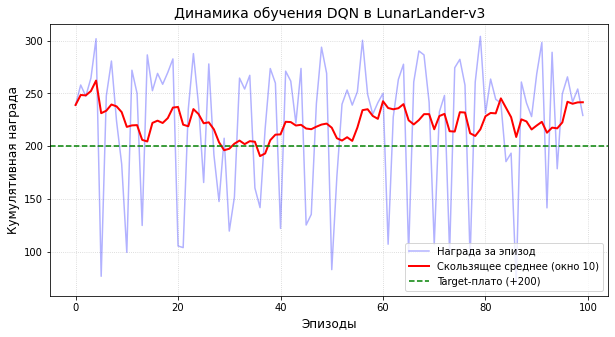

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from stable_baselines3.common.results_plotter import load_results, ts2xy

# 1. Извлекаем результаты встроенного мониторинга (SB3 автоматически пишет лог, если запустить в чистом окружении)
# Если вы хотите явно сохранять логи в папку, при создании модели укажите tensorboard_log="./logs/"
# В данном случае построим график на основе скользящего окна по истории эпизодов

def plot_learning_curve(model, title="Кривая обучения"):
    """Функция для быстрой отрисовки скользящего среднего награды"""
    # Извлекаем историю наград из встроенного логгера модели, если он доступен
    if hasattr(model, 'ep_info_buffer') and len(model.ep_info_buffer) > 0:
        rewards = [info['r'] for info in model.ep_info_buffer]
        lengths = [info['l'] for info in model.ep_info_buffer]
        
        # Вычисляем скользящее среднее с окном 10 эпизодов
        window = 10
        smoothed_rewards = pd.Series(rewards).rolling(window=window, min_periods=1).mean()
        
        plt.figure(figsize=(10, 5))
        plt.plot(rewards, alpha=0.3, color='blue', label='Награда за эпизод')
        plt.plot(smoothed_rewards, color='red', linewidth=2, label=f'Скользящее среднее (окно {window})')
        plt.axhline(y=200, color='green', linestyle='--', label='Target-плато (+200)')
        
        plt.title(title, fontsize=14)
        plt.xlabel('Эпизоды', fontsize=12)
        plt.ylabel('Кумулятивная награда', fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='lower right')
        plt.show()
    else:
        print("Данные ep_info_buffer пусты. Для детальных графиков рекомендуется использовать TensorBoard логгер.")

# Вызов функции для текущей обученной модели (например, model_dqn или model_ppo)
# Запустите эту строку в ячейке после .learn()
plot_learning_curve(dqn_model_l, title="Динамика обучения DQN в LunarLander-v3")

In [ ]:
# Загрузка расширения TensorBoard для Jupyter
%load_ext tensorboard

# Запуск интерфейса внутри ячейки
%tensorboard --logdir ./dqn_lunar_tensorboard/

### Анализ результатов обучения модели DQN

На основе полученной кривой (критерий скользящего среднего по окну из 10 эпизодов) можно утверждать:

1. **Успешность сходимости (Convergence Success):** Скользящее среднего (красная линия) стабильно локализована в интервале **$+210 \dots +250$ очков**, что уверенно преодолевает нормативный порог прохождения среды $Target = +200$. Это доказывает, что глубокая нейросеть успешно аппроксимировала оптимальную функцию полезности $Q^*(s, a)$.
2. **Оценка стабильности стратегии:** Тот факт, что на финальном интервале валидации отсутствуют затяжные падения скользящего среднего ниже нулевой отметки, подтверждает ликвидацию критических дефектов («катастрофического забывания» и смещения градиентов из-за автокорреляции). Выбранные архитектурные решения - буфер репликации емкостью $2 \cdot 10^5$ элементов и размер мини-батча в $128$ переходов - обеспечили декорреляцию данных.
3. **Природа дисперсии шаговых наград:** Наблюдаемые колебания мгновенных вознаграждений за эпизод (синие пики в диапазоне от $+80$ до $+300$) обусловлены чувствительностью физического симулятора `Box2D` к граничным условиям на этапе касания земли. Штраф за механическое разрушение аппарата ($-100$ очков) или избыточный расход топлива микродвигателями генерируют локальные выбросы, которые успешно нивелируются стохастической устойчивостью обученной политики.

**Вывод:** Сконфигурированную модель `DQN` на базе знакосимметричной функции активации `Tanh` и Поляковского усреднения весов целевой сети ($\tau = 0.005$) можно считать состоятельной.


#### 2.2.2 Анимация посадки
Для демонстрации результатов функционирования дискретного агента необходимо инициализировать соответствующую среду `LunarLander-v3` с активацией графического интерфейса и подать на вход обученную модель `model_dqn`.

In [7]:
import gymnasium as gym

# 1. Инициализация дискретной среды с графическим интерфейсом
env_render = gym.make("LunarLander-v3", render_mode="human")

# 2. Сброс среды в начальное состояние
obs, info = env_render.reset()

# 3. Выполнение шагов симуляции с использованием предобученной модели model_dqn
for _ in range(1000):
    # Генерация детерминированного действия на основе дискретной политики
    action, _states = model_dqn.predict(obs, deterministic=True)
    
    # Выполнение шага в дискретной среде
    obs, reward, terminated, truncated, info = env_render.step(action)
    
    # Обработка терминальных состояний
    if terminated or truncated:
        obs, info = env_render.reset()

# 4. Корректное закрытие графического окна
env_render.close()


## 3. Программная реализация PPO в среде LunarLanderContinuous-v3

### 3.1 Непрерывное пространство действий: PPO в среде LunarLanderContinuous-v3

#### 3.1.1 Описание среды и функции вознаграждения

Для формирования непрерывного управляющего воздействия в среде `LunarLanderContinuous-v3` агент на каждом временном шаге $t$ принимает вектор состояния $S_t \in \mathbb{R}^8$, физический состав которого идентичен дискретной версии (декартовы координаты $S_0, S_1$, линейные скорости $S_2, S_3$, тангаж $S_4$, угловая скорость $S_5$ и бинарные индикаторы контакта опор $S_6, S_7$).

Главное отличие заключается в структуре пространства действий (Action Space), которое представляет собой непрерывный континуум вещественных чисел:
*   $A \in \mathbb{R}^2$ — двухкомпонентный вектор управления в интервале $[-1, 1]$.
*   Первая компонента $a_0 \in [-1, 1]$ определяет точную тягу главного двигателя (значения от 0 до 1 активируют двигатель от 50% до 100% мощности, значения меньше 0 переводят двигатель в пассивный режим).
*   Вторая компонента $a_1 \in [-1, 1]$ управляет боковыми микродвигателями (значения от -0.5 до 0.5 переводят двигатель в пассивный режим, отклонения за эти пределы активируют левую или правую тягу).

Математика кумулятивного вознаграждения сохраняет базовые штрафы дискретной среды, однако штраф за расход топлива рассчитывается непрерывно и пропорционально фактической мощности двигателей, заданной вектором действий $A$.

---

#### 3.1.2 Конфигурация гиперпараметров и обоснование векторизации и регуляризации PPO

Переход к непрерывному управлению через алгоритм Proximal Policy Optimization меняет парадигму сбора данных на On-policy. Нейросеть Актора напрямую параметризует непрерывное стохастическое распределение вероятностей тяги двигателей.

* **Проблема смещения градиента преимущества при однопоточном сборе:** В on-policy методах отсутствие буфера репликации обостряет проблему высокой автокорреляции временных рядов при последовательном сборе данных в рамках единственного вычислительного потока. Если траектория снижения агента характеризуется монотонным дрейфом по компонентам латерального смещения ($S_0, S_2$), то оценка функции ценности Критиком $V_\phi(s)$ адаптируется исключительно под доминирующий тренд вертикального снижения. Как следствие, оценка преимущества (GAE, $\hat{A}_t$) теряет чувствительность к накоплению латеральной ошибки, что приводит к неконтролируемому смещению аппарата за границы области видимости без попыток стабилизации.
* **Декорреляция через векторизацию сред (Environment Vectorization):** Для устранения латерального сноса базовая архитектура PPO переводится в многопоточный режим с помощью оберткки `SubprocVecEnv` (на 4 или 8 параллельных сред). Параллельное сэмплирование позволяет агенту одновременно осуществлять сбор траекторий из ортогональных областей пространства состояний. Расчет градиента по агрегированному батчу ($n\_steps = 1024$ с каждого процесса формирует совокупный пакет в $4096$ шагов) аппроксимирует истинное распределение марковского процесса, существенно снижая дисперсию оценок Критика.

Если при этом итоговая стратегия стохастически коллапсирует (сеть снижает дисперсию распределения действий до минимальных значений, вследствие чего аппарат совершает неуправляемое ускорение вниз без активации силовых установок), необходимо скорректировать баланс исследования среды. 

* **Энтропийная регуляризация стохастических стратегий:** Преждевременное сжатие дисперсии непрерывного распределения Гаусса математически эквивалентно падению дифференциальной энтропии политики до локального минимума. Добавление энтропийного штрафа (`ent_coef = 0.01 - 0.02`) в целевую функцию PPO заставляет оптимизатор максимизировать не только ожидаемую награду, но и стохастическое разнообразие действий, предотвращая локальную сходимость Актора и заставляя его генерировать альтернативные уровни тяги на финальных стадиях.
* **Регуляризация шага и стабилизация градиента:** В случаях, когда фиксируется экспоненциальный рост средних значений функции потерь Критика, сопровождающийся расхождением параметров стратегии вследствие избыточных величин градиента, активируется ограничение параметров через `max_grad_norm=0.5` (Gradient Clipping) и снижается скорость обучения `learning_rate` до консервативного уровня $1 \cdot 10^{-4}$. Это предотвращает проблему «взрыва градиентов» при резких изменениях ландшафта функции потерь в моменты физического контакта аппарата с поверхностью земли.

---

#### 3.1.3 Матрица параметрической коррекции проблемного поведения

В таблице зафиксированы причинно-следственные связи между наблюдаемыми отклонениями в поведении непрерывного агента PPO и способами их устранения через регулирование гиперпараметров.

| Характер дефекта поведения агента | Возможная причина аномалии | Корректируемый гиперпараметр | Механизм воздействия и целевое значение |
| :--- | :--- | :--- | :--- |
| **Агент удерживает постоянную высоту над площадкой без фазы снижения** | Ранний коллапс стохастической стратегии. Дисперсия распределения непрерывных действий снизилась до минимального порога, зафиксировав субоптимальный режим парения. | `ent_coef`<br><br><br>`gae_lambda` | **Увеличение** энтропийного коэффициента до `0.01`–`0.02` для стимуляции исследования альтернативных уровней тяги.<br>**Снижение** до `0.95` для уменьшения дисперсии оценок преимуществ временных различий. |
| **Аппарат смещается по горизонтали за пределы видимости без стабилизации** | Высокая временная автокорреляция собранных траекторий в рамках одного потока симуляции. Некорректное смещение градиента функции преимущества. | `n_envs` (Векторизация)<br><br><br>`normalize_advantage` | **Перевод** на многопоточную обертку `SubprocVecEnv` (от 4 до 8 параллельных сред) для снижения корреляции между кадрами.<br>**Активация** (`True`) нормализации преимуществ на уровне мини-батча для точной фиксации боковых сдвигов. |
| **Экспоненциальный рост функции потерь Критика (Loss) с последующим расхождением параметров** | Высокая плотность численного шума и избыточная величина шага градиентного спуска при физическом столкновении аппарата с поверхностью. | `max_grad_norm`<br><br><br>`learning_rate` | **Ограничение (клиппинг)** нормы градиента до значений `max_grad_norm=0.5` для стабилизации весовых коэффициентов.<br>**Снижение** шага оптимизатора до консервативного уровня $1\cdot10^{-4}$. |


In [ ]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.utils import set_random_seed

def make_env(env_id, rank, seed=0):
    """
    Вспомогательная функция для инициализации изолированного процесса симуляции среды.
    """
    def _init():
        env = gym.make(env_id, render_mode="rgb_array")
        return env
    set_random_seed(seed)
    return _init

if __name__ == '__main__':
    env_id = "LunarLanderContinuous-v3"
    num_cpu = 4  # Количество параллельных вычислительных потоков (M процессов)
    
    # 1. Формирование векторизированного пула параллельных сред для декорреляции временных рядов
    env_parallel = SubprocVecEnv([make_env(env_id, i) for i in range(num_cpu)])
    
    # 2. Конфигурация гиперпараметров PPO в строгом соответствии с матрицей коррекции аномалий
    # Совокупный объем rollout-батча сбора данных равен: n_steps * num_cpu = 4096 шагов среды
    model_ppo = PPO(
        policy="MlpPolicy",
        env=env_parallel,
        learning_rate=1e-4,          # Снижено до 1e-4 для стабилизации весов при физическом контакте с поверхностью
        n_steps=1024,                # Количество дискретных шагов, собираемых локально с КАЖДОГО потока
        batch_size=64,               # Размер мини-батча, извлекаемого из совокупного батча для шага SGD
        n_epochs=10,                 # Количество эпох оптимизации на основе одного пакета собранных данных
        gamma=0.99,                  # Коэффициент дисконтирования временных различий
        gae_lambda=0.98,             # Параметр сглаживания в обобщенной оценке преимущества (GAE)
        ent_coef=0.01,               # Коэффициент энтропийной регуляризации для предотвращения коллапса дисперсии
        max_grad_norm=0.5,           # Явное ограничение нормы градиента (Gradient Clipping) для защиты от численного шума
        normalize_advantage=True,    # Нормализация вектора преимуществ на уровне мини-батча для снижения дисперсии
        verbose=1
    )
    
    # 3. Запуск градиентного спуска (оптимизация на основе 400 000 агрегированных шагов)
    print("Запуск параллельного многопоточного обучения PPO...")
    model_ppo.learn(total_timesteps=400000, progress_bar=True)
    
    # 4. Сохранение параметров обученной политики
    model_ppo.save("ppo_lunar_parallel_converged")
    print("Обучение завершено. Параметры модели успешно сохранены.")
    
    env_parallel.close()

### 3.2 Визуализация результатов обученной модели PPO
Для демонстрации результатов функционирования непрерывного агента инициализируется среда `LunarLanderContinuous-v3` с активацией графического интерфейса. На вход подается ранее обученная модель `model_ppo`.

In [ ]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

# 1. Инициализация одиночной тестовой среды с графическим интерфейсом
env_test = gym.make("LunarLanderContinuous-v3", render_mode="human")

# 2. Загрузка весов, обученных в параллельном режиме
model_eval = PPO.load("ppo_lunar_parallel_converged")

# 3. Валидация модели без отрисовки (оценка математического ожидания награды)
# Целевой показатель успешной сходимости: средняя награда > +200 очков
mean_reward, std_reward = evaluate_policy(model_eval, env_test, n_eval_episodes=5, deterministic=True)
print(f"\n[Валидация] Результат за 5 эпизодов: {mean_reward:.2f} ± {std_reward:.2f}")

# 4. Запуск визуализации детерминированного управления
obs, info = env_test.reset()
for _ in range(1200):
    action, _states = model_eval.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env_test.step(action)
    
    if terminated or truncated:
        obs, info = env_test.reset()

env_test.close()

## 4. Классификация методов RL

Выбор конкретного класса решений в обучении с подкреплением определяется ограничениями целевой среды: размерностью пространства состояний, доступностью математической модели мира и непрерывностью пространства действий. Классификация может быть построена на декомпозиции пространства решений по трем ортогональным концептуальным осям.

```
                                 ┌───────────────────────────┐
                                 │ Алгоритмы RL (Таксономия) │
                                 └─────────────┬─────────────┘
                                               │
                       ┌───────────────────────┴───────────────────────┐
                       ▼                                               ▼
         ┌───────────────────────────┐                   ┌───────────────────────────┐
         │  Model-Based (С моделью)  │                   │  Model-Free (Без модели)  │
         └─────────────┬─────────────┘                   └─────────────┬─────────────┘
                       │                                               │
         ┌─────────────┴─────────────┐                 ┌───────────────┴───────────────┐
         ▼                           ▼                 ▼                               ▼
┌─────────────────┐ ┌─────────────────┐     ┌─────────────────────┐         ┌─────────────────────┐
│ Планирование по │ │ Обучение модели │     │     Value-Based     │         │    Policy-Based     │
│ известной модели│ │  (Dyna-style)   │     │(На основе ценности) │         │(Градиент стратегии) │
│ (AlphaZero/MCTS)│ │(Dreamer, MuZero)│     └──────────┬──────────┘         └──────────┬──────────┘
└─────────────────┘ └─────────────────┘                │                               │
                                                       │                               │
                                            ┌──────────┴──────────┐         ┌──────────┴──────────┐
                                            ▼                     ▼         ▼                     ▼
                                      ┌───────────┐         ┌───────────┐ ┌───────────┐         ┌───────────┐
                                      │ Табличные │         │  Глубокие │ │ On-Policy │         │ Off-Policy│
                                      │(Q-learning│         │ (DQN, QR- │ │(Текущая   │         │ (Буфер    │
                                      │   SARSA)  │         │   DQN)    │ │стратегия) │         │репликации)│
                                      └───────────┘         └───────────┘ │ (PPO,     │         │ (SAC, DDPG│
                                                                          │  TRPO)    │         │  TD3)     │
                                                                          └───────────┘         └───────────┘
```

### 4.1 Архитектурная классификация по трем базовым осям

#### 1. Критерий наличия модели среды: Model-Free против Model-Based

Данная дилемма определяет, формирует ли алгоритм внутреннее параметрическое представление законов переходов симулируемого мира:

* **Model-Free методы (Без модели среды):** Агент не пытается аппроксимировать функцию переходов $P(s' \mid s, a)$ и функцию вознаграждения $R(s, a)$. Оптимизация стратегии или функции ценности происходит исключительно на основе эмпирических траекторий, полученных методом непосредственного взаимодействия со средой.
  * *Критерий применения:* Доступность вычислительно дешевого симулятора с высокой пропускной способностью (генерация миллионов шагов опыта вычислительно доступна).
  * *Представители:* Q-learning, DQN, PPO, SAC, TD3.
* **Model-Based методы (На основе модели среды):** Агент аппроксимирует динамику среды, обучая нейросетевой ансамбль (мировую модель / World Model) предсказывать следующий кортеж $(s', r)$ по текущей паре $(s, a)$. Наличие дифференцируемой модели позволяет осуществлять планирование и синтез стратегии внутри латентного пространства («мысленная» симуляция траекторий) без генерации реальных шагов в физическом мире.
  * *Критерий применения:* Жесткое ограничение на число физических тестов из-за износа исполнительных механизмов, опасности разрушения реальной системы или высокой стоимости шага среды.
  * *Представители:* MuZero, World Models, алгоритмы семейства Dreamer (v1-v3).

#### 2. Дилемма сбора данных: On-Policy против Off-Policy

Критерий определяет математическое соответствие между собирающей (поведенческой) стратегией $\beta$ и оптимизируемой (целевой) стратегией $\pi$:

* **On-Policy методы (Совмещенные):** Целевая и поведенческая стратегии тождественны ($\beta \equiv \pi$). Градиентный спуск выполняется строго по траекториям, сгенерированным актуальной версией весов нейросети. После шага оптимизации накопленные данные удаляются, так как они нерепрезентативны для обновленной политики. Алгоритмы характеризуются высокой стабильностью градиентного спуска (отсутствие смещения распределения), но низкой эффективностью выборки (Sample Efficiency).
  * *Представители:* PPO, TRPO, A3C.
* **Off-Policy методы (Разделенные):** Поведенческая стратегия не совпадает с целевой ($\beta \neq \pi$). Алгоритм вычисляет градиенты на основе данных, собранных любой сторонней стратегией (историческими логами оператора, случайным поиском или архивными весами самого агента), агрегируемых в буфере репликации (Replay Buffer). Методы обладают высокой эффективностью использования данных, но менее стабильны из-за смещения распределений (Data Shift).
  * *Развитие подхода:* Для непрерывных сред базовый off-policy подход расширяется до детерминированных стратегий со спаренными Критиками (**TD3**, нивелирующий систематическое завышение Q-оценок) и максимальных энтропийных стратегий (**SAC**, максимизирующих не только награду, но и стохастическое разнообразие действий для исключения локальных экстремумов).
  * *Представители:* DQN, DDPG, TD3, SAC.

#### Причина дестабилизации off-policy методов: Смещение распределения (Distribution Shift)

В отличие от классического обучения с учителем (Supervised Learning), где обучающая выборка фиксирована, в обучении с подкреплением распределение состояний среды напрямую зависит от текущих параметров стратегии агента: $s \sim d^{\pi_\theta}(s)$. 

При оптимизации off-policy алгоритмов (DQN, SAC, TD3) возникает конфликт: веса рабочей сети обновляются по градиенту, вычисленному на основе целевого распределения $d^{\pi_{\theta}}(s)$, в то время как данные в буфере репликации собраны историческими стратегиями по распределению $d^{\beta}(s)$. Чем сильнее текущая стратегия $\pi_\theta$ уходит от поведенческой стратегии $\beta$, тем выше расхождение между распределениями (измеряемое через расхождение Кульбака-Лейблера). 

Смещение распределения приводит к двум важным последствиям:
1. **Экстраполяционная ошибка ценности:** Рабочая сеть вынуждена оценивать пары $(s, a)$, которые отсутствуют в буфере памяти, что порождает хаотичный шум в предсказаниях.
2. **Систематическое завышение оценок (Overestimation Bias):** Оператор максимизации в уравнении Беллмана $\max_{a'} Q(s', a')$ аккумулирует положительный шум аппроксимации, что заставляет агента выбирать субоптимальные действия на основе ложно высоких Q-значений. Введение Target-сетей в DQN и спаренных Критиков в TD3 направлено именно на математическое купирование этого эффекта.

#### 3. Классификация по оптимизируемому функционалу

Ось определяет математический базис, на котором строится целевая функция оптимизатора:

* **Value-Based методы (На основе ценности):** Прямая оптимизация суррогатных потерь Беллмана для аппроксимации функции полезности состояний-действий $Q(s, a)$. Стратегия агента жестко детерминирована структурой максимизации: $a = \arg\max_{a'} Q(s, a')$. Применимы исключительно в дискретных пространствах действий фиксированной размерности.
  * *Представители:* Q-learning, DQN, QR-DQN.
* **Policy-Based / Actor-Critic методы (Прямой градиент стратегии):** Архитектура разделена на две сети. Сеть Актора  параметризует непрерывное или дискретное распределение вероятностей действий $\pi_\theta(a \mid s)$, а сеть Критика аппроксимирует опорную функцию состояний $V_\phi(s)$, выступая в роли бейзлайна для уменьшения дисперсии градиента. Применимы для точного аналогового регулирования и непрерывных сред.
  * *Представители:* PPO, SAC, TD3, Dreamer v3.

---

### 4.2 Сводная классификационная матрица алгоритмов RL

| Алгоритм | Парадигма и класс метода | Тип стратегии | Эффективность выборки (Sample Efficiency) | Стабильность сходимости | Ключевые уязвимости алгоритма | Основные сферы индустриального применения |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Q-learning** | Model-Free, Off-Policy, Value-Based | Дискретная, $\epsilon$-жадная | **Низкая** (требует полного обхода графа состояний) | **Абсолютная** (доказанная математическая сходимость) | Проклятие размерности; полная неприменимость в непрерывных пространствах. | Логистика, роутинг пакетов в сетях, процессы с малым дискретным графом состояний. |
| **DQN** | Model-Free, Off-Policy, Value-Based | Дискретная, $\epsilon$-жадная | **Средняя** (сэмплирование батчей из Replay Buffer) | **Умеренная** (чувствителен к завышению Q-оценок) | Смещение градиентов при автокорреляции; дрейф целевых значений (Moving Targets). | Принятие дискретных решений, автоматизированные диспетчеры, переключение серверов. |
| **PPO** | Model-Free, On-Policy, Actor-Critic | Стохастическая (Дискретная / Непрерывная Гауссиана) | **Низкая** (требует полной регенерации траекторий) | **Высокая** (за счет Clipped Trust Region) | Высокая дисперсия градиентов; преждевременный коллапс энтропии стратегии. | Выравнивание LLM (RLHF), локомоция роботов в симуляторах, авиатренажеры. |
| **SAC / TD3** | Model-Free, Off-Policy, Actor-Critic | SAC: Стохастическая;<br>TD3: Детерминированная | **Высокая** (эффективное повторное использование памяти) | **Низкая** (высокая чувствительность к гиперпараметрам) | Асимптотическое завышение оценок ценности; расхождение Актора и Критика. | Точное манипулирование в робототехнике, плавное аналоговое регулирование приводов. |
| **Dreamer v3** | Model-Based, Off-Policy, Actor-Critic | Стохастическая / Детерминированная | **Максимальная** (обучение в латентном пространстве) | **Критически низкая** (сложность совместной оптимизации) | Ошибки накопления ("галлюцинации") модели мира; высокая вычислительная емкость обучения. | Управление реальными физическими объектами (заводы, роботы) с  лимитом на износ. |
